In [1]:
import numpy as np
import scipy
from scipy.stats import beta, boltzmann
from typing import Tuple
import sys
import os
import librosa
import matplotlib.pyplot as plt

project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.append(project_root)

from modules.Pyin import PyinPitchExtractor

pitch_extractor = PyinPitchExtractor()

[-2.9673258e-05 -3.6110661e-05 -3.8504204e-05 ...  1.5642506e-03
  1.8349856e-03  2.0253770e-03]


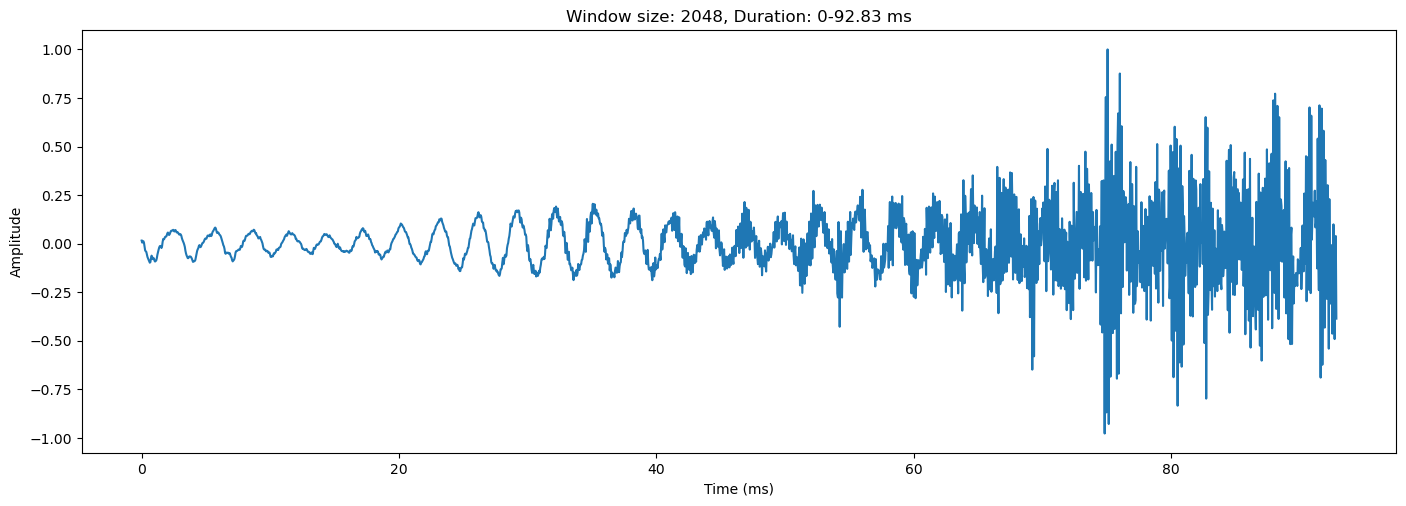

In [2]:
y, sr = librosa.load('./birds_of_feather.wav')
print(y[:10000])
windows_size = int(2048)
window_start = np.random.randint(0, len(y) - windows_size)
window_end = window_start + windows_size
window = y[window_start:window_end]
window = window / (np.max(np.abs(window)) + 1e-10) 

time_ms = np.arange(len(window)) * 1000 / sr

plt.figure(figsize=(14, 5))
plt.plot(time_ms, window)

plt.title(f'Window size: {windows_size}, Duration: 0-{time_ms[-1]:.2f} ms')
plt.xlabel('Time (ms)')
plt.ylabel('Amplitude')
plt.tight_layout(pad=0.5) # add padding to avoid overlap
plt.show()

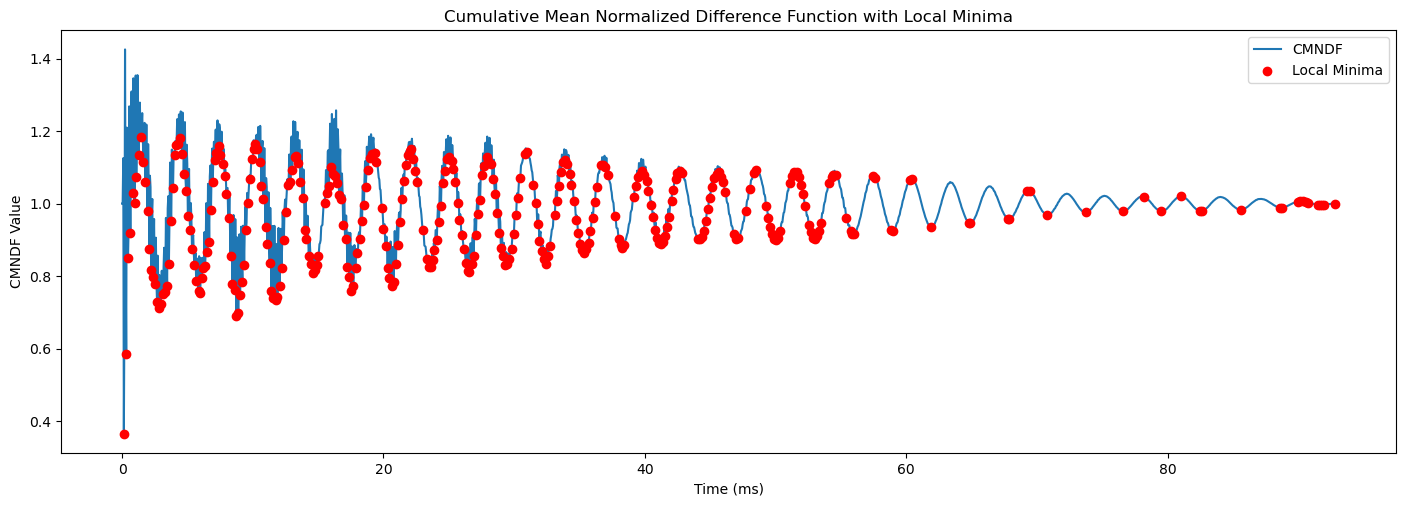

In [3]:
diff = pitch_extractor._difference_function(window)
cmndf = pitch_extractor._cumulative_mean_normalized_difference_function(diff)
local_minima, local_minima_index = pitch_extractor._find_local_minimas(cmndf)
plt.figure(figsize=(14, 5))
plt.plot(time_ms, cmndf, label='CMNDF')
plt.scatter(time_ms[local_minima_index], local_minima, color='red', label='Local Minima', zorder=5)
plt.title('Cumulative Mean Normalized Difference Function with Local Minima')
plt.xlabel('Time (ms)')
plt.ylabel('CMNDF Value')
plt.legend()
plt.tight_layout(pad=0.5)
plt.show()


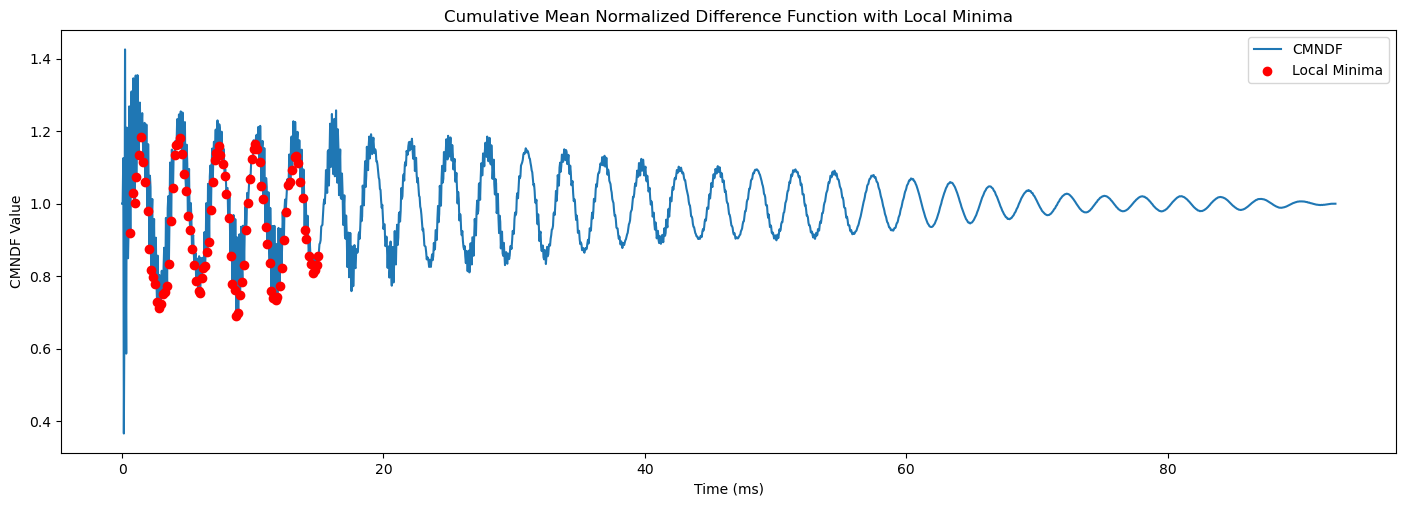

In [4]:
diff = pitch_extractor._difference_function(window)
cmndf = pitch_extractor._cumulative_mean_normalized_difference_function(diff)
local_minima, local_minima_index = pitch_extractor._find_local_minimas(cmndf)
filtered_local_minima, filtered_minima_index = pitch_extractor._filter_local_minimas(local_minima, local_minima_index)
plt.figure(figsize=(14, 5))
plt.plot(time_ms, cmndf, label='CMNDF')
plt.scatter(time_ms[filtered_minima_index], filtered_local_minima, color='red', label='Local Minima', zorder=5)
plt.title('Cumulative Mean Normalized Difference Function with Local Minima')
plt.xlabel('Time (ms)')
plt.ylabel('CMNDF Value')
plt.legend()
plt.tight_layout(pad=0.5)
plt.show()


[1575.         1225.         1050.          918.75        787.5
  689.0625      612.5         565.38461538  512.79069767  479.34782609
  450.          424.03846154  400.90909091  373.72881356  355.64516129
  339.23076923  319.56521739  306.25        290.13157895  279.11392405
  265.6626506   256.39534884  247.75280899  242.30769231  234.57446809
  225.          218.31683168  212.01923077  204.16666667  198.64864865
  191.73913043  186.86440678  180.73770492  176.4         170.93023256
  167.04545455  164.55223881  160.94890511  157.5         153.125
  150.          147.          144.11764706  141.34615385  138.67924528
  135.27607362  132.8313253   129.70588235  127.4566474   125.28409091
  122.5         120.49180328  118.5483871   116.05263158  114.24870466
  112.5         110.8040201   108.62068966  107.03883495  105.50239234
  104.00943396  102.08333333  100.22727273   98.87892377   98.
   96.71052632   95.04310345   93.82978723   92.64705882   91.11570248
   90.           88.554216

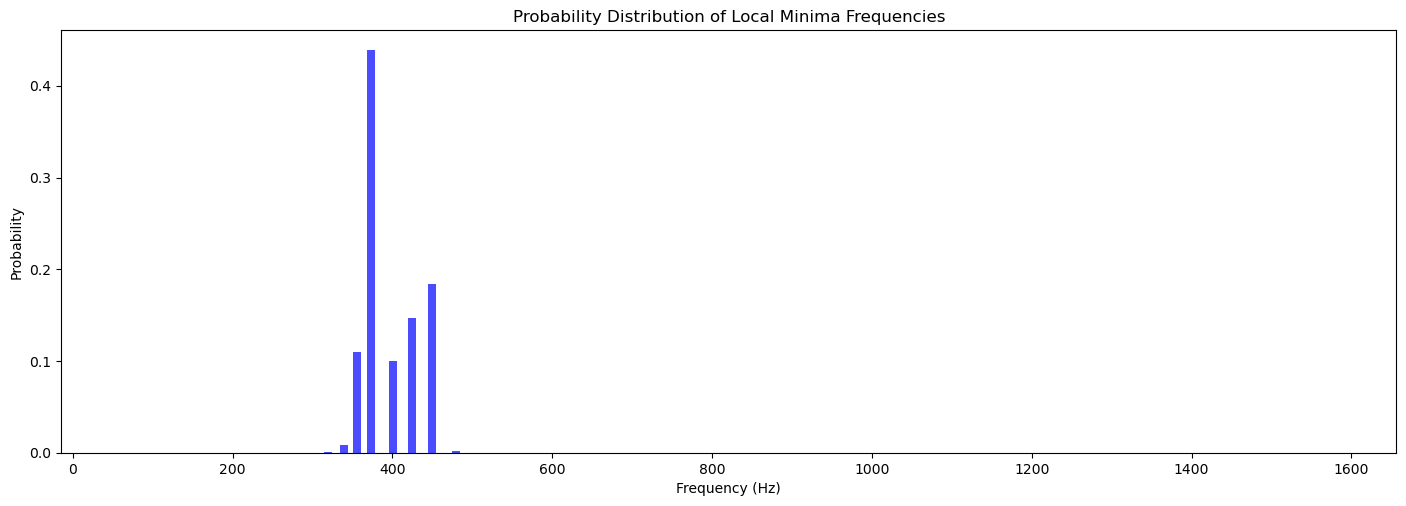

In [5]:
real_local_minima, local_minima_probs = pitch_extractor._frame_wise_pitch_extraction(window)
sr = pitch_extractor.sample_rate
local_minima_freqs = sr / filtered_minima_index
print(local_minima_freqs)
print(np.sum(local_minima_probs))

plt.figure(figsize=(14, 5))
plt.bar(local_minima_freqs, local_minima_probs, width=10, color='blue', alpha=0.7)
plt.title('Probability Distribution of Local Minima Frequencies')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Probability')
plt.tight_layout(pad=0.5)
plt.show()


In [6]:
f0, f0_probs, time_series = pitch_extractor.signal_pitch_extraction(y)

In [7]:
# plt.plot(librosa.pyin(y, fmin=65, fmax=2093, sr=sr)[0])
from modules.PitchSmoother import PitchSmoother
pitch_smoother = PitchSmoother(f0, f0_probs, sample_rate=sr)
states = pitch_smoother._viterbi_decoding()
observation_matrix = pitch_smoother._build_observation_matrix()
f0_smoothed = pitch_smoother._state_to_freq(states, obs_matrix=observation_matrix)

[358 358 358 ... 619 619 619]
Frequency: 362.946, Start Time: 0.0, End Time: 0.3482993197278912
Frequency: 356.011, Start Time: 0.3482993197278912, End Time: 0.5572789115646258
Frequency: 349.228, Start Time: 0.5572789115646258, End Time: 0.5804988662131519
Frequency: 342.575, Start Time: 0.5804988662131519, End Time: 0.626938775510204
Frequency: 329.628, Start Time: 0.626938775510204, End Time: 0.9752380952380952
Frequency: 323.348, Start Time: 0.9752380952380952, End Time: 1.0216780045351475
Frequency: 329.628, Start Time: 1.0216780045351475, End Time: 1.0681179138321997
Frequency: 342.575, Start Time: 1.0681179138321997, End Time: 1.0913378684807256
Frequency: 329.628, Start Time: 1.0913378684807256, End Time: 1.486077097505669
Frequency: 342.575, Start Time: 1.486077097505669, End Time: 1.509297052154195
Frequency: 349.228, Start Time: 1.509297052154195, End Time: 1.5557369614512473
Frequency: 342.575, Start Time: 1.5557369614512473, End Time: 1.6950566893424037
Frequency: 362.946,

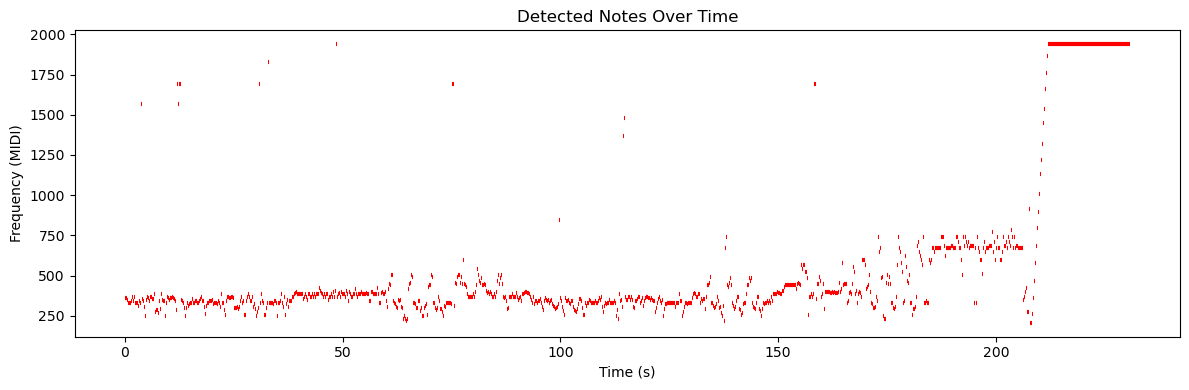

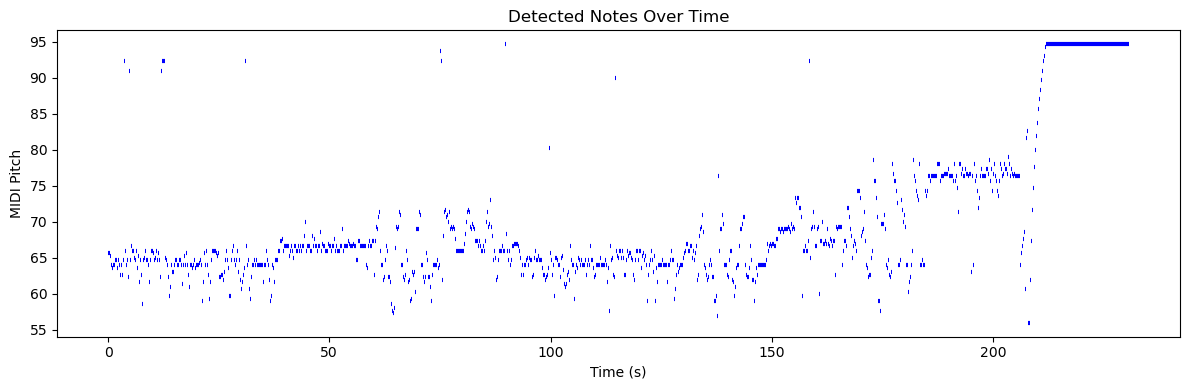

In [8]:
from modules.NoteSegmentation import NoteSegmentation
note_segmentation = NoteSegmentation()

viterbi = note_segmentation._viterbi_decoding(f0_smoothed)
post_processed = note_segmentation.post_process(viterbi)
# Print frequency, start time, and end time for each post-processed note
for note in post_processed:
    print(f"Frequency: {note['frequency'].round(3)}, Start Time: {note['start_time']}, End Time: {note['end_time']}")
# Plot notes as horizontal lines over time
plt.figure(figsize=(12, 4))
for note in post_processed:
    plt.hlines(note['frequency'], note['start_time'], note['end_time'], colors='r', linewidth=3)
plt.xlabel('Time (s)')
plt.ylabel('Frequency (MIDI)')
plt.title('Detected Notes Over Time')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
for note in post_processed:
    plt.hlines(note['midi_pitch'], note['start_time'], note['end_time'], colors='blue', linewidth=3)
plt.xlabel('Time (s)')
plt.ylabel('MIDI Pitch')
plt.title('Detected Notes Over Time')
plt.tight_layout()
plt.show()

In [9]:
import mido

# Create a new MIDI file and track
mid = mido.MidiFile()
track = mido.MidiTrack()
mid.tracks.append(track)

# Set tempo (default 500000 microseconds per beat = 120 BPM)
tempo = 500000
track.append(mido.MetaMessage('set_tempo', tempo=tempo))

# MIDI time conversion helpers
def seconds_to_ticks(seconds, tempo, ticks_per_beat):
    beats = seconds * 1e6 / tempo
    return int(beats * ticks_per_beat)

ticks_per_beat = mid.ticks_per_beat

# Sort notes by start_time
notes_sorted = sorted(post_processed, key=lambda n: n['start_time'])

last_tick = 0
for note in notes_sorted:
    midi_pitch = int(round(note['midi_pitch']))
    start_tick = seconds_to_ticks(note['start_time'], tempo, ticks_per_beat)
    end_tick = seconds_to_ticks(note['end_time'], tempo, ticks_per_beat)
    duration = end_tick - start_tick

    # Add note_on
    track.append(mido.Message('note_on', note=midi_pitch, velocity=64, time=start_tick - last_tick))
    # Add note_off
    track.append(mido.Message('note_off', note=midi_pitch, velocity=64, time=duration))
    last_tick = end_tick

# Save to file
mid.save('output.mid')